# 04 · Answering the question with the output table

**Question:** what is the typical price paid for a property in each municipality, each year, counting only sales the County codes as valid, of a single parcel?

This notebook reads only the gold table. It checks how much each year can be trusted, then looks at how prices moved, whether all places moved the same way, and what one municipality looks like row by row.

The queries live in `pipeline/insights.py`, shared with the dashboard (`dashboard/home_sale_prices.html`), so the notebook, the dashboard and the README quote the same numbers. Each cell prints its SQL above the result, and a chart follows each table.

In [1]:
import matplotlib.pyplot as plt

from helpers import BLUE, MUTED, ORANGE, RAMP, connect, df, dollars, plot_style, show
from pipeline import insights as Q

con, years = connect()
G = Q.G
MIN_SALES = Q.MIN_SALES          # valid sales a row needs to be used in comparisons (30)
plot_style()

show(f"SELECT * FROM {G} LIMIT 10")
show(Q.overview(), echo=True)

┌───────────┬───────────┬────────────────────────┬──────────────────┬──────────────┬───────────┬───────────┬───┬───────────┬──────────────────┬────────────────────────┬─────────────────┬────────────────┬───────────────┐
│ sale_year │ muni_code │       muni_desc        │ valid_sales_used │ median_price │ p25_price │ p75_price │ … │ pct_valid │ pct_undetermined │ valid_records_excluded │ is_partial_year │ is_provisional │ is_low_sample │
│   int64   │  varchar  │        varchar         │      int64       │    int64     │   int64   │   int64   │ … │  double   │      double      │         int64          │     boolean     │    boolean     │    boolean    │
├───────────┼───────────┼────────────────────────┼──────────────────┼──────────────┼───────────┼───────────┼───┼───────────┼──────────────────┼────────────────────────┼─────────────────┼────────────────┼───────────────┤
│      2012 │ 101       │ 1st Ward  - PITTSBURGH │                2 │         NULL │      NULL │      NULL │ … │       2

**What this shows:** 2,618 rows for 175 municipalities and Pittsburgh wards, 2012–2026. Together they cover all 506,977 records:
- 114,611 are coded valid
- 298 of those are left out (deed with several parcels or several dates, placeholder deed, no price, or the same parcel and date on two deeds)
- 114,313 are used for the prices

2,169 rows have a median; the other 449 have fewer than 5 valid sales. A typical row is based on 19 sales, which is too few to compare reliably. So for comparisons I only use rows with at least 30 sales (`MIN_SALES`).

## 1. How far can each year be trusted?

**Question:** before looking at any price: in each year, how many records are coded valid, how many haven't been reviewed by the County yet, and how many municipalities have enough sales to compare?

In [2]:
show(Q.coverage_by_year(), rows=50, echo=True)

# The latest year whose numbers are final, used as the end point below
LATEST = Q.latest_complete_year(con)
print("latest complete year:", LATEST)

SELECT sale_year,
       sum(records_total) AS records,
       sum(valid_sales_used) AS valid_sales_used,
       round(100.0 * sum(records_valid) / sum(records_total), 1) AS pct_valid,
       round(100.0 * sum(records_undetermined) / sum(records_total), 1) AS pct_undetermined,
       count(*) FILTER (WHERE valid_sales_used >= 30) AS municipalities_comparable,
       count(*) FILTER (WHERE median_price IS NULL) AS rows_without_median,
       bool_or(is_partial_year) AS partial, bool_or(is_provisional) AS provisional
FROM gold.valid_sale_prices_by_municipality_year GROUP BY 1 ORDER BY 1

┌───────────┬─────────┬──────────────────┬───────────┬──────────────────┬───────────────────────────┬─────────────────────┬─────────┬─────────────┐
│ sale_year │ records │ valid_sales_used │ pct_valid │ pct_undetermined │ municipalities_comparable │ rows_without_median │ partial │ provisional │
│   int64   │ int128  │      int128      │  double   │      double      │           int64           │        in

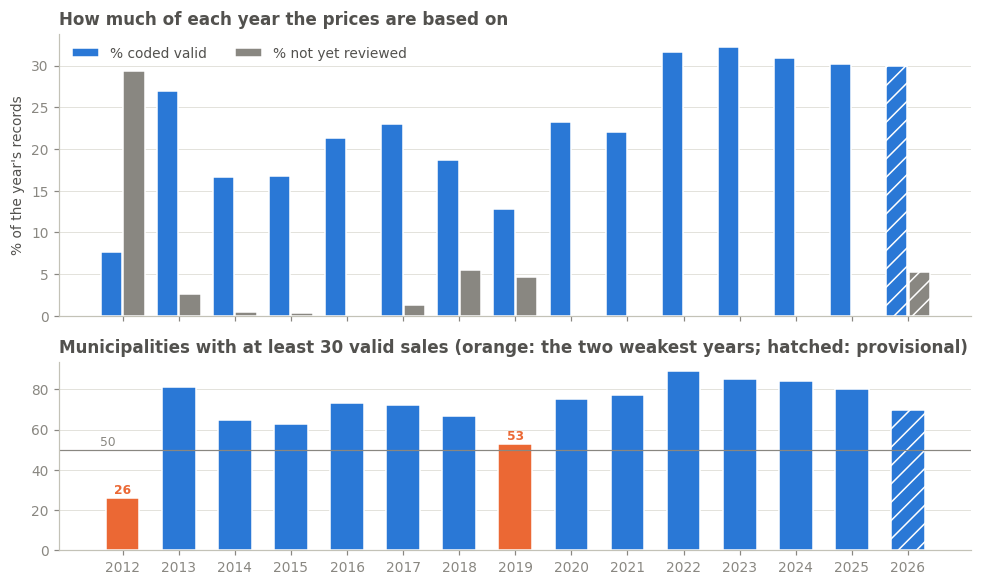

In [3]:
cov = df(Q.coverage_by_year())
weak = set(cov[~cov.provisional].nsmallest(2, "pct_valid").sale_year)   # the two weakest final years
x = cov.sale_year
hatch = ["//" if p else "" for p in cov.provisional]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.bar(x - 0.2, cov.pct_valid, 0.38, color=BLUE, hatch=hatch, edgecolor="white", label="% coded valid")
top.bar(x + 0.2, cov.pct_undetermined, 0.38, color=MUTED, hatch=hatch, edgecolor="white", label="% not yet reviewed")
top.set_title("How much of each year the prices are based on")
top.set_ylabel("% of the year's records")
top.legend(loc="upper left", ncols=2)

bottom.bar(x, cov.municipalities_comparable, 0.6, color=[ORANGE if y in weak else BLUE for y in x],
           hatch=hatch, edgecolor="white")
bottom.axhline(Q.MIN_MUNICIPALITIES, color=MUTED, linewidth=0.8)
bottom.text(x.min() - 0.4, Q.MIN_MUNICIPALITIES + 2, f"{Q.MIN_MUNICIPALITIES}", color=MUTED, fontsize=8)
for y in weak:
    n = int(cov.loc[cov.sale_year == y, "municipalities_comparable"].iloc[0])
    bottom.text(y, n + 2, str(n), ha="center", color=ORANGE, fontsize=8, fontweight="bold")
bottom.set_title(f"Municipalities with at least {MIN_SALES} valid sales (orange: the two weakest years; hatched: provisional)")
bottom.set_xticks(x)
plt.tight_layout()
plt.show()

*Chart:* the top panel shows the share of records coded valid and not yet reviewed; the bottom shows how many municipalities have enough sales to compare. The two weakest final years are orange, the provisional year hatched.

**What this shows:**
- **2012 is the weakest year.** Only 7.7% of its records are coded valid and 29.4% haven't been reviewed yet. Only 26 municipalities have enough sales, and 77 rows have no median.
- **2019 is the next weakest:** 12.8% valid, 53 municipalities with enough sales, 40 rows without a median. 2014, 2015 and 2018 are also below 20% valid.
- **From 2022 on** it's steady: about 30% valid, 80–89 municipalities with enough sales, and nothing left unreviewed until 2026.
- **2026 isn't finished** and its codes are still being reviewed, so the last complete year (`LATEST`) is **2025**.

**So:** how many records are coded valid depends on how the County coded each year, not on the market. That means the number of sales per year doesn't show market activity. 2012 and 2019 are based on few sales, and the 2012 level should be ignored (only 26 municipalities). I compare prices within each municipality, not as county totals.

## 2. How did the typical price move?

**Question:** what was the median of a typical municipality each year, and how much did it change from one year to the next?

The yearly change is measured inside each municipality: this year's median ÷ last year's, for municipalities with enough sales in both years. Then I take the median of those changes. This way, a different set of municipalities in one year can't create a change on its own.

In [4]:
show(Q.typical_change(), rows=50, echo=True)

# The year with the largest typical change, used to split the period below
JUMP = Q.jump_year(con)
print("year with the largest typical change:", JUMP)

WITH level AS (
    SELECT sale_year, count(*) AS municipalities, median(median_price) AS typical_median
    FROM gold.valid_sale_prices_by_municipality_year WHERE valid_sales_used >= 30 GROUP BY 1
), change AS (
    SELECT b.sale_year, count(*) AS municipalities_both_years,
           round(100 * (median(b.median_price * 1.0 / a.median_price) - 1), 1) AS typical_change_pct,
           round(100.0 * avg((b.median_price > a.median_price)::INT), 0) AS pct_municipalities_up
    FROM gold.valid_sale_prices_by_municipality_year a JOIN gold.valid_sale_prices_by_municipality_year b ON b.muni_code = a.muni_code AND b.sale_year = a.sale_year + 1
    WHERE a.valid_sales_used >= 30 AND b.valid_sales_used >= 30
    GROUP BY 1
)
SELECT * FROM level LEFT JOIN change USING (sale_year) ORDER BY sale_year

┌───────────┬────────────────┬────────────────┬───────────────────────────┬────────────────────┬───────────────────────┐
│ sale_year │ municipalities │ typical_median │ municipalities_both_years │ ty

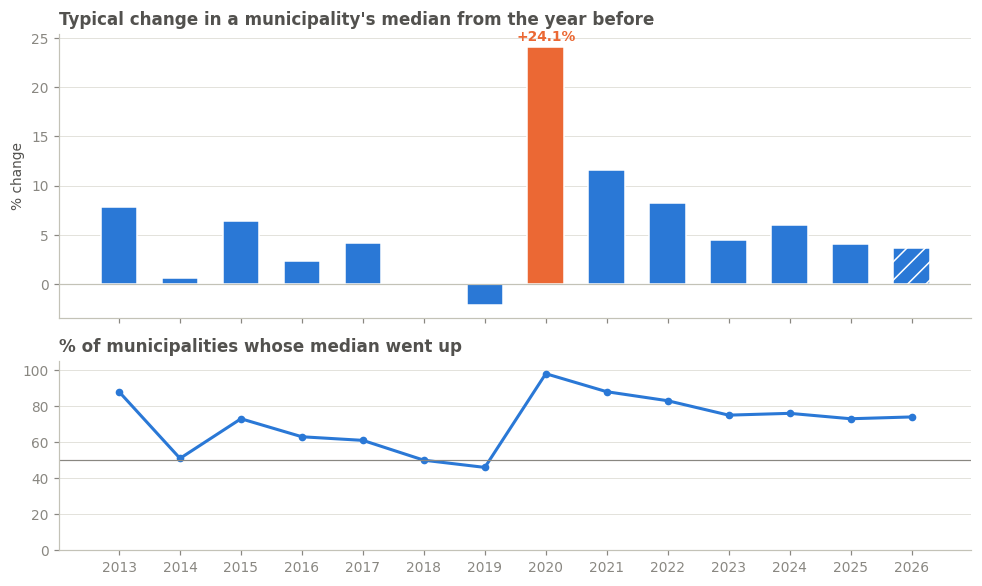

In [5]:
chg = df(Q.typical_change()).dropna(subset=["typical_change_pct"])
prov = df(Q.coverage_by_year()).set_index("sale_year").provisional
x = chg.sale_year
hatch = ["//" if prov[y] else "" for y in x]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.bar(x, chg.typical_change_pct, 0.6, color=[ORANGE if y == JUMP else BLUE for y in x], hatch=hatch, edgecolor="white")
top.axhline(0, color="#c3c2b7", linewidth=0.8)
j = chg[chg.sale_year == JUMP].iloc[0]
top.text(JUMP, j.typical_change_pct + 0.6, f"+{j.typical_change_pct:.1f}%", ha="center", color=ORANGE, fontweight="bold")
top.set_title("Typical change in a municipality's median from the year before")
top.set_ylabel("% change")

bottom.plot(x, chg.pct_municipalities_up, color=BLUE, marker="o", markersize=4)
bottom.axhline(50, color=MUTED, linewidth=0.8)
bottom.set_ylim(0, 105)
bottom.set_title("% of municipalities whose median went up")
bottom.set_xticks(x)
plt.tight_layout()
plt.show()

*Chart:* the top panel is the typical within-municipality change each year, with the jump year in orange and the provisional year hatched; the bottom is the share of municipalities that went up (line at 50%).

**What this shows:**
- **The level column depends on which municipalities are included.** 2012's typical median ($160,625) is higher than 2013's ($132,700) only because 2012 has 26 municipalities instead of 81. That's why I measure the change inside each municipality.
- **2013–2019:** the typical yearly change stays between −2.1% and +7.8%, and in 2018 and 2019 only about half of municipalities went up (50%, 46%).
- **2020 is the biggest change in the table: +24.1%, with 98% of municipalities up.** The query saves it as `JUMP`.
- **After that:** +11.6% in 2021, then +4% to +8% a year, with about three quarters of municipalities going up each year.

**So:** prices rose slowly until 2019 (1.12× from 2013 to 2019 in §3, about 2% a year), jumped in 2020, and have grown steadily since. The jump isn't caused by coverage: 2020 has normal coverage (23.3% valid), and the change is measured in the same municipalities in both years.

## 3. Did all places move the same way?

**Question:** did cheap and expensive municipalities go up at the same rate? For each start year, I split municipalities into four groups (quarters) by their median that year, and measure how much each group grew up to the last complete year.

In [6]:
show(Q.quarter_growth(LATEST), rows=50, echo=True)

WITH pairs AS (
    SELECT a.sale_year AS start_year, a.muni_code, a.median_price AS start_median,
           b.median_price * 1.0 / a.median_price AS growth
    FROM gold.valid_sale_prices_by_municipality_year a JOIN gold.valid_sale_prices_by_municipality_year b ON b.muni_code = a.muni_code AND b.sale_year = 2025
    WHERE a.sale_year < 2025 AND a.valid_sales_used >= 30 AND b.valid_sales_used >= 30
), quartered AS (
    SELECT *, ntile(4) OVER (PARTITION BY start_year ORDER BY start_median) AS price_quarter FROM pairs
)
PIVOT (SELECT start_year, 'Q' || price_quarter AS q, growth FROM quartered)
ON q USING round(median(growth), 2)
ORDER BY start_year

┌────────────┬────────┬────────┬────────┬────────┐
│ start_year │   Q1   │   Q2   │   Q3   │   Q4   │
│   int64    │ double │ double │ double │ double │
├────────────┼────────┼────────┼────────┼────────┤
│       2012 │   2.32 │   2.07 │   2.01 │   1.84 │
│       2013 │   2.32 │    2.0 │   1.94 │   1.82 │
│       2014 │    2.3 │   1.96 │  

In [7]:
# The whole period split at the jump year: growth before and after, per municipality
show(Q.before_after(JUMP, LATEST), echo=True)

WITH y AS (SELECT muni_code, sale_year, median_price AS p FROM gold.valid_sale_prices_by_municipality_year WHERE valid_sales_used >= 30),
first_ AS (SELECT min(sale_year) AS y FROM y WHERE sale_year < 2020 - 1
           AND sale_year IN (SELECT sale_year FROM y GROUP BY 1 HAVING count(*) >= 50))
SELECT (SELECT y FROM first_) AS from_year, 2020 - 1 AS split_year, 2025 AS to_year,
       count(*) AS municipalities,
       round(median(b.p * 1.0 / a.p), 2) AS typical_growth_before,
       round(median(c.p * 1.0 / b.p), 2) AS typical_growth_after,
       count(*) FILTER (WHERE c.p > b.p) AS rose_after
FROM y a JOIN y b USING (muni_code) JOIN y c USING (muni_code)
WHERE a.sale_year = (SELECT y FROM first_) AND b.sale_year = 2020 - 1 AND c.sale_year = 2025

┌───────────┬────────────┬─────────┬────────────────┬───────────────────────┬──────────────────────┬────────────┐
│ from_year │ split_year │ to_year │ municipalities │ typical_growth_before │ typical_growth_after │ rose_after │
│   int64

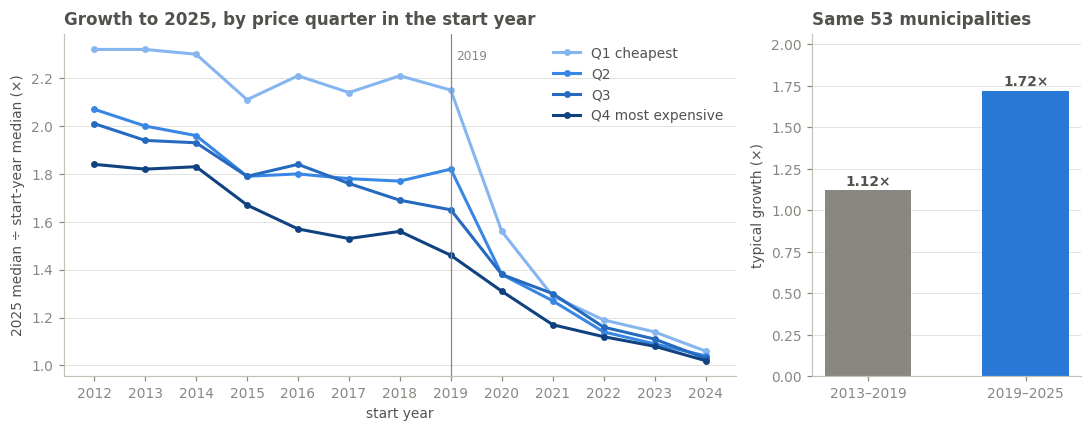

In [8]:
qg = df(Q.quarter_growth(LATEST))
ba = df(Q.before_after(JUMP, LATEST)).iloc[0]
names = {"Q1": "Q1 cheapest", "Q2": "Q2", "Q3": "Q3", "Q4": "Q4 most expensive"}

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [3, 1.2]})
for q, colour in zip(["Q1", "Q2", "Q3", "Q4"], RAMP):
    left.plot(qg.start_year, qg[q], color=colour, marker="o", markersize=3.5, label=names[q])
left.axvline(JUMP - 1, color=MUTED, linewidth=0.8)
left.text(JUMP - 1 + 0.1, qg[["Q1", "Q2", "Q3", "Q4"]].max().max(), f"{JUMP - 1}", color=MUTED, fontsize=8, va="top")
left.set_title(f"Growth to {LATEST}, by price quarter in the start year")
left.set_ylabel(f"{LATEST} median ÷ start-year median (×)")
left.set_xlabel("start year")
left.set_xticks(qg.start_year)
left.legend(loc="upper right")

labels = [f"{int(ba.from_year)}–{int(ba.split_year)}", f"{int(ba.split_year)}–{int(ba.to_year)}"]
values = [ba.typical_growth_before, ba.typical_growth_after]
right.bar(labels, values, 0.55, color=[MUTED, BLUE])
for i, v in enumerate(values):
    right.text(i, v + 0.03, f"{v:.2f}×", ha="center", fontweight="bold")
right.set_ylim(0, max(values) * 1.2)
right.set_title(f"Same {int(ba.municipalities)} municipalities")
right.set_ylabel("typical growth (×)")
plt.tight_layout()
plt.show()

*Chart:* on the left, each line is one price quarter (light = cheapest, dark = most expensive) and shows how much it grew from the start year to the last complete year; on the right, growth before and after the split year for the same municipalities.

**What this shows:**
- **Every start year gives the same order:** the cheapest quarter (Q1) grows the most up to 2025, and the most expensive (Q4) the least. From 2019 that's 2.15× vs 1.46×; from 2013, 2.32× vs 1.82×.
- **The gap opened before 2021.** From 2021 onward the four quarters grow almost the same (1.29 vs 1.17 from 2021, 1.06 vs 1.02 from 2024).
- **Before and after the jump:** I split at 2019 (the year before `JUMP`) and start at 2013, the first year with at least 50 municipalities to compare. The 53 municipalities with enough sales in all three years grew 1.12× from 2013 to 2019, and **1.72× from 2019 to 2025. All 53 went up.**

**So:** every municipality with enough sales to measure went up, and the cheapest ones went up the most, mostly during the 2020–2021 jump. *Assumption:* the mix of property types sold in each place stayed about the same; the table has no property type.

## 4. Do places keep their order, and how far apart are they?

**Question:** each year, how far apart are the cheapest and most expensive municipalities, and does their ranking change from one year to the next?

In [9]:
show(Q.spread_and_rank(), rows=50, echo=True)

WITH ranked AS (
    SELECT sale_year, muni_code, median_price, rank() OVER (PARTITION BY sale_year ORDER BY median_price) AS r
    FROM gold.valid_sale_prices_by_municipality_year WHERE valid_sales_used >= 30
), spread AS (
    SELECT sale_year, count(*) AS municipalities,
           quantile_cont(median_price, 0.1)::BIGINT AS p10_median, median(median_price)::BIGINT AS typical_median,
           quantile_cont(median_price, 0.9)::BIGINT AS p90_median,
           round(quantile_cont(median_price, 0.9) / quantile_cont(median_price, 0.1), 2) AS p90_to_p10
    FROM ranked GROUP BY 1
), order_kept AS (
    SELECT b.sale_year, round(corr(a.r, b.r), 2) AS rank_corr_with_previous_year
    FROM ranked a JOIN ranked b ON b.muni_code = a.muni_code AND b.sale_year = a.sale_year + 1
    GROUP BY 1
)
SELECT * FROM spread LEFT JOIN order_kept USING (sale_year) ORDER BY sale_year

┌───────────┬────────────────┬────────────┬────────────────┬────────────┬────────────┬──────────────────────────────┐
│ s

In [10]:
# Highest and lowest in the latest complete year
show(Q.highest_lowest(LATEST), echo=True)

(SELECT 'highest' AS end_, muni_desc, median_price, p25_price, p75_price, valid_sales_used FROM gold.valid_sale_prices_by_municipality_year
 WHERE sale_year = 2025 AND valid_sales_used >= 30 ORDER BY median_price DESC LIMIT 5)
UNION ALL
(SELECT 'lowest', muni_desc, median_price, p25_price, p75_price, valid_sales_used FROM gold.valid_sale_prices_by_municipality_year
 WHERE sale_year = 2025 AND valid_sales_used >= 30 ORDER BY median_price LIMIT 5)

┌─────────┬────────────────────────┬──────────────┬───────────┬───────────┬──────────────────┐
│  end_   │       muni_desc        │ median_price │ p25_price │ p75_price │ valid_sales_used │
│ varchar │        varchar         │    int64     │   int64   │   int64   │      int64       │
├─────────┼────────────────────────┼──────────────┼───────────┼───────────┼──────────────────┤
│ highest │ Fox Chapel             │       977000 │    691814 │   1292500 │               48 │
│ highest │ Pine                   │       675000 │    446500 │    856250 

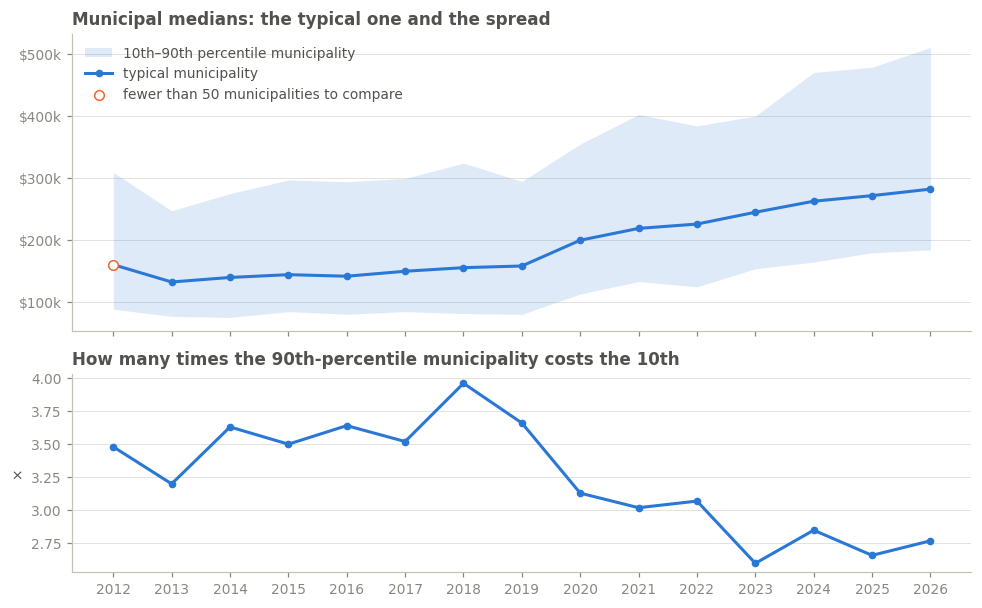

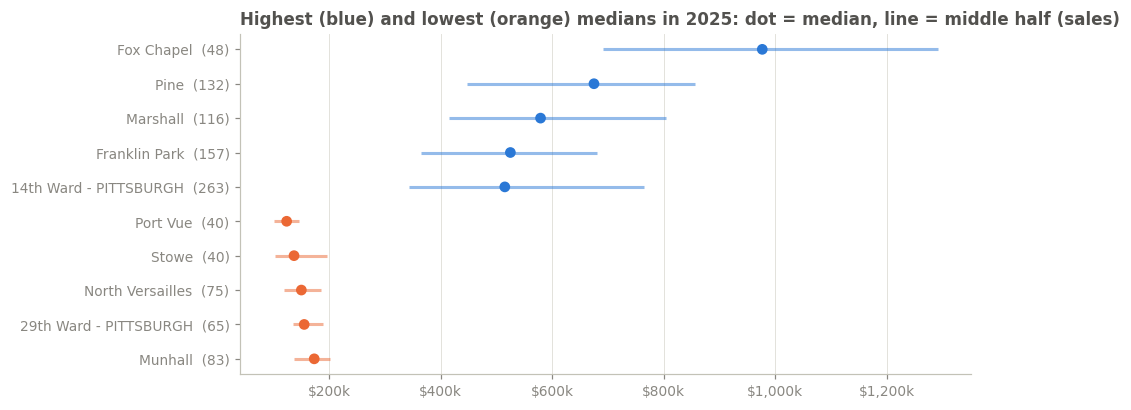

In [11]:
sp = df(Q.spread_and_rank())
thin = sp.municipalities < Q.MIN_MUNICIPALITIES      # too few municipalities to read the county level
x = sp.sale_year

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.fill_between(x, sp.p10_median, sp.p90_median, color=BLUE, alpha=0.15, linewidth=0, label="10th–90th percentile municipality")
top.plot(x, sp.typical_median, color=BLUE, marker="o", markersize=4, label="typical municipality")
top.scatter(x[thin], sp.typical_median[thin], s=40, facecolor="white", edgecolor=ORANGE, zorder=3,
            label=f"fewer than {Q.MIN_MUNICIPALITIES} municipalities to compare")
dollars(top)
top.set_title("Municipal medians: the typical one and the spread")
top.legend(loc="upper left")

bottom.plot(x, sp.p90_to_p10, color=BLUE, marker="o", markersize=4)
bottom.set_title("How many times the 90th-percentile municipality costs the 10th")
bottom.set_ylabel("×")
bottom.set_xticks(x)
plt.tight_layout()
plt.show()

ends = df(Q.highest_lowest(LATEST)).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = range(len(ends))
colour = [BLUE if e == "highest" else ORANGE for e in ends.end_]
ax.hlines(y, ends.p25_price, ends.p75_price, color=colour, linewidth=2, alpha=0.5)
ax.scatter(ends.median_price, y, color=colour, s=36, zorder=3)
ax.set_yticks(list(y), [f"{d.strip()}  ({n})" for d, n in zip(ends.muni_desc, ends.valid_sales_used)])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
dollars(ax, "x")
ax.set_title(f"Highest (blue) and lowest (orange) medians in {LATEST}: dot = median, line = middle half (sales)")
plt.tight_layout()
plt.show()

*Chart:* the first chart is the typical municipal median with the band from the 10th to the 90th percentile municipality (hollow orange: too few municipalities to read the level), and how far apart the two ends are; the second shows the five highest and lowest in the last complete year.

**What this shows:**
- **The ranking hardly moves.** Each year's ranking matches the year before very closely (rank correlation 0.95–0.98). Expensive places stay expensive and cheap places stay cheap.
- **The gap got smaller after the jump.** The municipality at the 90th percentile cost 3.2–4.0× the one at the 10th until 2019, 3.0–3.1× in 2020–2022, and 2.6–2.85× from 2023. The 10th percentile more than doubled ($80,605 in 2019 → $179,710 in 2025), while the 90th rose about 60% ($294,700 → $478,500).
- **Highest and lowest in 2025** (at least 30 sales): Fox Chapel $977,000 (48 sales), Pine $675,000 and Marshall $579,125 at the top; Port Vue $123,500, Stowe $136,750 and North Versailles $149,900 at the bottom. Pittsburgh wards show up at both ends (14th Ward $515,000, 29th Ward $155,000).

**So:** places move together and keep their order, but the gap between the cheapest and most expensive has been closing since 2020. This matches §3: the cheaper places rose faster.

## 5. The answer for one municipality

**Question:** what does the answer look like for one municipality, year by year? I use the municipality with the most valid sales over all years, so every year has a reliable median.

In [12]:
MUNI = Q.most_sales_municipality(con)
show(Q.one_municipality(MUNI), rows=50, echo=True)

SELECT sale_year, muni_desc, median_price, p25_price, p75_price, valid_sales_used,
       pct_valid, pct_undetermined, is_low_sample, is_provisional
FROM gold.valid_sale_prices_by_municipality_year WHERE muni_code = '934' ORDER BY sale_year

┌───────────┬────────────┬──────────────┬───────────┬───────────┬──────────────────┬───────────┬──────────────────┬───────────────┬────────────────┐
│ sale_year │ muni_desc  │ median_price │ p25_price │ p75_price │ valid_sales_used │ pct_valid │ pct_undetermined │ is_low_sample │ is_provisional │
│   int64   │  varchar   │    int64     │   int64   │   int64   │      int64       │  double   │      double      │    boolean    │    boolean     │
├───────────┼────────────┼──────────────┼───────────┼───────────┼──────────────────┼───────────┼──────────────────┼───────────────┼────────────────┤
│      2012 │ Penn Hills │        79450 │     65000 │     92250 │               60 │       5.6 │             34.8 │ false         │ false          │
│      2013 │

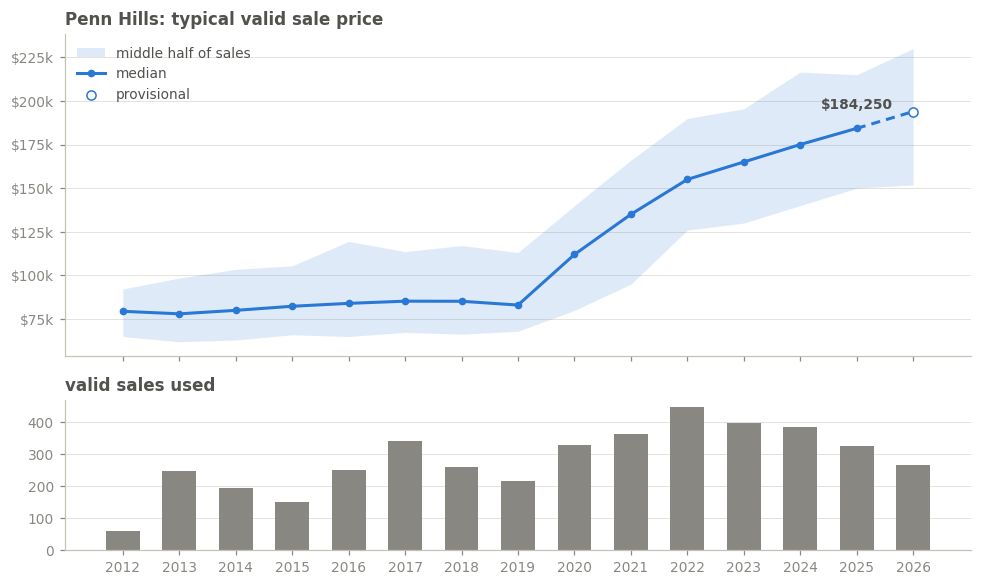

In [13]:
m = df(Q.one_municipality(MUNI))
final, prov = m[~m.is_provisional], m[m.is_provisional]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
top.fill_between(m.sale_year, m.p25_price, m.p75_price, color=BLUE, alpha=0.15, linewidth=0, label="middle half of sales")
top.plot(final.sale_year, final.median_price, color=BLUE, marker="o", markersize=4, label="median")
if len(prov):
    tail = m.iloc[-2:]
    top.plot(tail.sale_year, tail.median_price, color=BLUE, linestyle=(0, (3, 2)))
    top.scatter(prov.sale_year, prov.median_price, s=36, facecolor="white", edgecolor=BLUE, zorder=3, label="provisional")
last = final.iloc[-1]
top.text(last.sale_year, last.median_price * 1.06, f"${last.median_price:,.0f}", ha="center", fontweight="bold")
dollars(top)
top.set_title(f"{m.muni_desc.iloc[0]}: typical valid sale price")
top.legend(loc="upper left")

bottom.bar(m.sale_year, m.valid_sales_used, 0.6, color=MUTED)
bottom.set_title("valid sales used")
bottom.set_xticks(m.sale_year)
plt.tight_layout()
plt.show()

*Chart:* the median for each year with the middle half of sales shaded (the provisional year hollow and dashed), and the number of valid sales behind each year.

**What this shows:** Penn Hills has the most valid sales over all years, so every one of its rows is reliable (60 to 447 sales, never `is_low_sample`). Its typical sale stayed at $78,000–85,250 from 2012 to 2019, rose to $112,000 in 2020 and $135,000 in 2021, and reached $184,250 in 2025 (middle half $150,000–$215,000, 325 sales). That's 2.2× from 2019 to 2025, the same pattern as the cheaper quarter in §3. Its 2012 row also shows the coverage problem from §1: 5.6% valid and 34.8% not yet reviewed.

**So:** one row answers the question for one municipality and year, and the columns next to the price show how much it can be trusted.